<a href="https://colab.research.google.com/github/Park-wonil/BigdataPrac/blob/main/Stock.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
url = 'https://stock.naver.com/api/stockSecurity/items/v2/domestic/005930/daily-prices?size=100'
response = requests.get(url)
print(response.status_code)

200


In [12]:
response.text[:100]#딕셔너리
type(response.json())
response.json()
list(response.json())
response.json()['items']#100개불러와서 100개len값
len(response.json()['items'])#진짜 주가정보들어있는것만
type(response.json()['items'])#아까 리스트로 만들어서 리스트타입
response.json()['items'][0]#최근
response.json()['items'][1]#다음


'리스트 안에 동일한 키로 구성된 딕셔너리로 데이터 프레임 만들기'

In [51]:
df = pd.DataFrame(response.json()['items'])
print(list(df))
df['closingPrice'][0]#종가 열 전체가져오기 그 앞에서 제일 첫번째 데이터
df.dtypes

['tradingDateKst', 'basePrice', 'closingPrice', 'changePrice', 'priceMovement', 'changeRate', 'openingPrice', 'highPrice', 'lowPrice', 'tradingVolume', 'tradingValue']


,0
tradingDateKst,object
basePrice,object
closingPrice,object
changePrice,object
priceMovement,object
changeRate,object
openingPrice,object
highPrice,object
lowPrice,object
tradingVolume,object


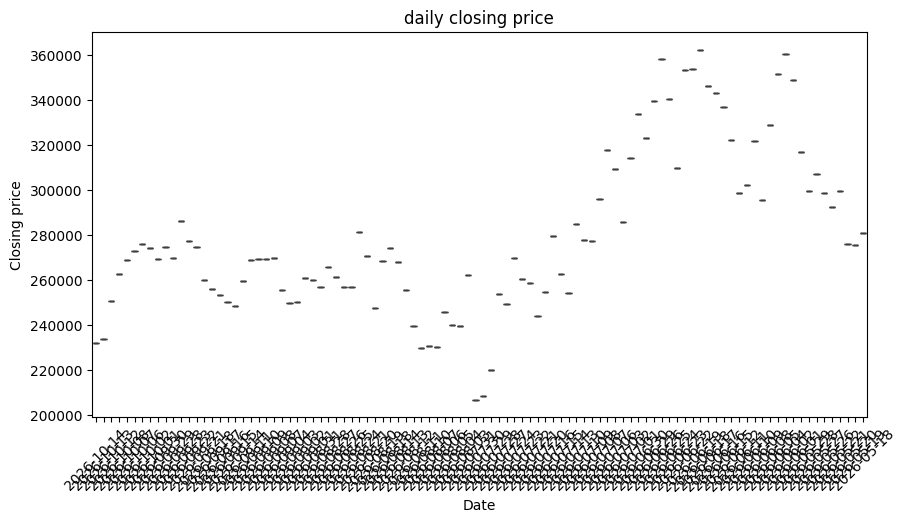

In [52]:
df["tradingDateKst"] = pd.to_datetime(df["tradingDateKst"]) #날짜데이터칸에있는걸 진짜 날짜로 인식하게 바꾸기
#df["tradingDateKst"] =pd.to_datetime(df["tradingDateKst"])
df['closingPrice'] = pd.to_numeric(df['closingPrice'], errors='coerce')

plt.figure(figsize=(10, 5))
sns.boxplot(
    data=df, x="tradingDateKst", y="closingPrice"
)  # x축에 일자열, y축에 값 지정

plt.xticks(rotation=45)  # 날짜가 겹칠 경우 X축 라벨 회전
plt.title("daily closing price")
plt.xlabel("Date")
plt.ylabel("Closing price")
plt.show()


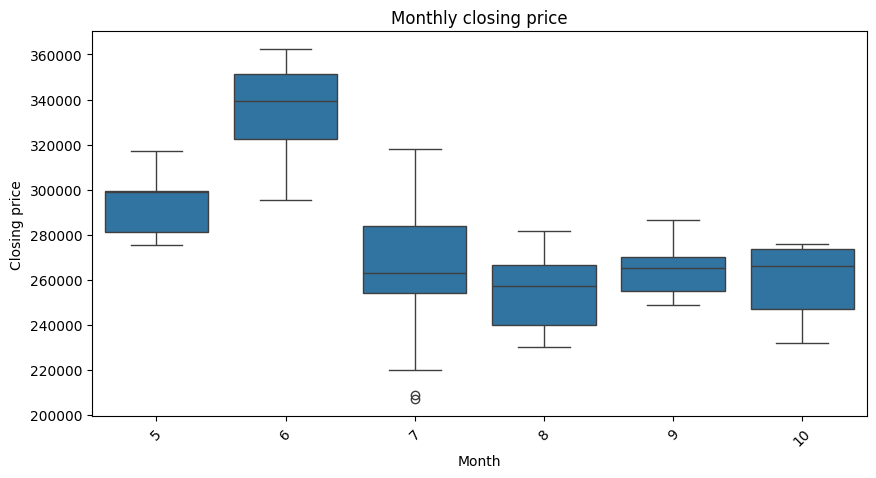

In [54]:
df["tradingDateKst"] = pd.to_datetime(df["tradingDateKst"])
df['closingPrice'] = pd.to_numeric(df['closingPrice'], errors='coerce')
df['Month'] = df['tradingDateKst'].dt.month#Month라는 새로운 열을만들어서 실제 달을 읽게

plt.figure(figsize=(10, 5))
sns.boxplot(
    data=df, x="Month", y="closingPrice"
)  # x축에 월열, y축에 값 지정

plt.xticks(rotation=45)  # 날짜가 겹칠 경우 X축 라벨 회전
plt.title("Monthly closing price")
plt.xlabel("Month")
plt.ylabel("Closing price")
plt.show()


In [63]:
def plus(a,b):
  c = a+b
  return c# 그냥 계산기 만들기
plus(10,200)

210

In [64]:
def get_stock_price(code, size = 100):
  url = f'https://stock.naver.com/api/stockSecurity/items/v2/domestic/{code}/daily-prices'

  headers = {'user-agent': 'Mozilla/5.0'}
  params = {'size': size}
  response = requests.get(url, params=params)

  df = pd.DataFrame(response.json()['items'])

  return df

  #주식데이터를 가져와서 표로만드는함수
  #code에 종목번호 적기

In [65]:
samsung = get_stock_price('005930')
samsung

,tradingDateKst,basePrice,closingPrice,changePrice,priceMovement,changeRate,openingPrice,highPrice,lowPrice,tradingVolume,tradingValue
0,2026-10-14,232000,233500,1500,rising,0.65,233500,241500,230000,16957325,3997766000000.000
1,2026-10-13,250500,234000,-16500,falling,-6.59,241500,244000,228000,26790913,6242963049500.000
2,2026-10-12,262000,251000,-11000,falling,-4.20,260000,262500,249000,19771955,5018226038736.000
3,2026-10-08,268500,263000,-5500,falling,-2.05,269500,270000,262000,21259056,5617134619618.000
4,2026-10-07,272000,269000,-3000,falling,-1.10,269500,279500,268000,16395504,4471785088086.000
...,...,...,...,...,...,...,...,...,...,...,...
95,2026-05-22,299500,292500,-7000,falling,-2.34,300000,300500,292000,18395274,5415999876319.000
96,2026-05-21,276000,299500,23500,rising,8.51,291000,299500,287000,36168689,10669803962580.000
97,2026-05-20,275500,276000,500,rising,0.18,278000,282500,263500,35662077,9744232201916.000
98,2026-05-19,281000,275500,-5500,falling,-1.96,274000,281500,266000,30767569,8425000673138.000


In [66]:
iter_list = [1, 2, 3, 4]
for i in range(len(iter_list)):
  print(iter_list[i])
  print(iter_list[i]*iter_list[i])
  print(2*iter_list[i])#배열기초

1
1
2
2
4
4
3
9
6
4
16
8


In [67]:
target = ['005930','000660']#두개다 가져옴

stock_df = pd.DataFrame()
print(len(stock_df))

for i in target:
  this_df = get_stock_price(i)
  print(len(this_df))
  this_df['code'] = i
  print(len(this_df))
  stock_df = pd.concat([stock_df, this_df])#원래거에 새로운거붙임
  print(len(stock_df))

stock_df.head()

0
100
100
100
100
100
200


,tradingDateKst,basePrice,closingPrice,changePrice,priceMovement,changeRate,openingPrice,highPrice,lowPrice,tradingVolume,tradingValue,code
0,2026-10-14,232000,234000,2000,rising,0.86,233500,241500,230000,16959375,3998245000000.000,005930
1,2026-10-13,250500,234000,-16500,falling,-6.59,241500,244000,228000,26790913,6242963049500.000,005930
2,2026-10-12,262000,251000,-11000,falling,-4.20,260000,262500,249000,19771955,5018226038736.000,005930
3,2026-10-08,268500,263000,-5500,falling,-2.05,269500,270000,262000,21259056,5617134619618.000,005930
4,2026-10-07,272000,269000,-3000,falling,-1.10,269500,279500,268000,16395504,4471785088086.000,005930


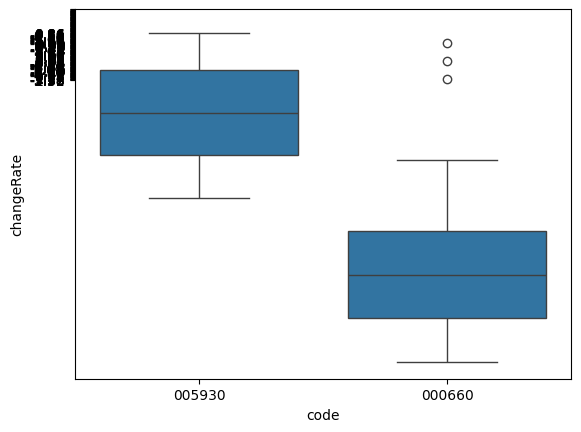

In [68]:
df["changeRate"] = pd.to_numeric(df["changeRate"])

sns.boxplot(x='code', y='changeRate', data=stock_df) #여기서 새로만들어진걸 씀
plt.yticks(np.arange(min(df["changeRate"]), max(df["changeRate"]), 0.2))

plt.show()